# 01 · Where is the pairing gap?

**Question:** which orders stay half-paired, what do people add when they do pair, and what is each add-on worth
at each branch?

**What we find**
- **Whether** an order gets paired barely moves with branch, hour, weekday or dine-in/takeaway (every cell sits within a
  few points of the average). It moves with **what was rung first**: a Matcha & Tea drink is joined by food 38% of the time, a hot coffee or cold drink only 20%.
- **What** gets added depends strongly on the first item's category: a matcha or tea rung first is followed by
  bakery 79% of the time; a sandwich or meal rung first is followed by a cold drink about 41% of the time (cold drinks
  are 18% of drink lines overall). Time of day matters much less.
- **The same add-on is worth different amounts at different branches.** Garden pays 1.43x Harbour's unit cost on
  every one of the 45 products (bottled water included) while charging slightly lower prices, so an add-on there earns
  much less. The engine must price per branch.
- **Discounts did not create pairs.** Orders with any discounted line look more paired (a counting artifact: bigger
  orders are more likely to contain a discounted line). When only the first drink was discounted, pairing was unchanged.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from storiespair import data, evidence, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)

## 1. Does context change *whether* an order gets paired?

Target: `paired` = the order ends up with an item from the other side of the first item rung. Rows are split by the
side of the first item, because "drink first" and "food first" are different situations at the till.

In [2]:
def rate_table(by):
    t = orders.groupby(["first_side", by]).paired.agg(["mean", "size"]).reset_index()
    return t.pivot(index=by, columns="first_side", values="mean").round(3)

for by in ["branch", "daypart", "order_type", "weekend", "known_customer"]:
    t = rate_table(by)
    print(f"\nPaired rate by {by}  (range across groups: drink-first {t['drink'].max()-t['drink'].min():.3f}, "
          f"food-first {t['food'].max()-t['food'].min():.3f})")
    print(t.to_string())


Paired rate by branch  (range across groups: drink-first 0.004, food-first 0.007)
first_side  drink   food
branch                  
Garden      0.258  0.313
Harbour     0.256  0.316
Uptown      0.254  0.309

Paired rate by daypart  (range across groups: drink-first 0.028, food-first 0.030)
first_side  drink   food
daypart                 
Afternoon   0.256  0.320
Evening     0.267  0.304
Midday      0.239  0.334
Morning     0.245  0.305

Paired rate by order_type  (range across groups: drink-first 0.003, food-first 0.012)
first_side  drink   food
order_type              
Dine-in     0.255  0.309
Takeaway    0.258  0.321

Paired rate by weekend  (range across groups: drink-first 0.003, food-first 0.022)
first_side  drink   food
weekend                 
False       0.256  0.309
True        0.259  0.331

Paired rate by known_customer  (range across groups: drink-first 0.002, food-first 0.010)
first_side      drink  food
known_customer             
False           0.258  0.32
True        

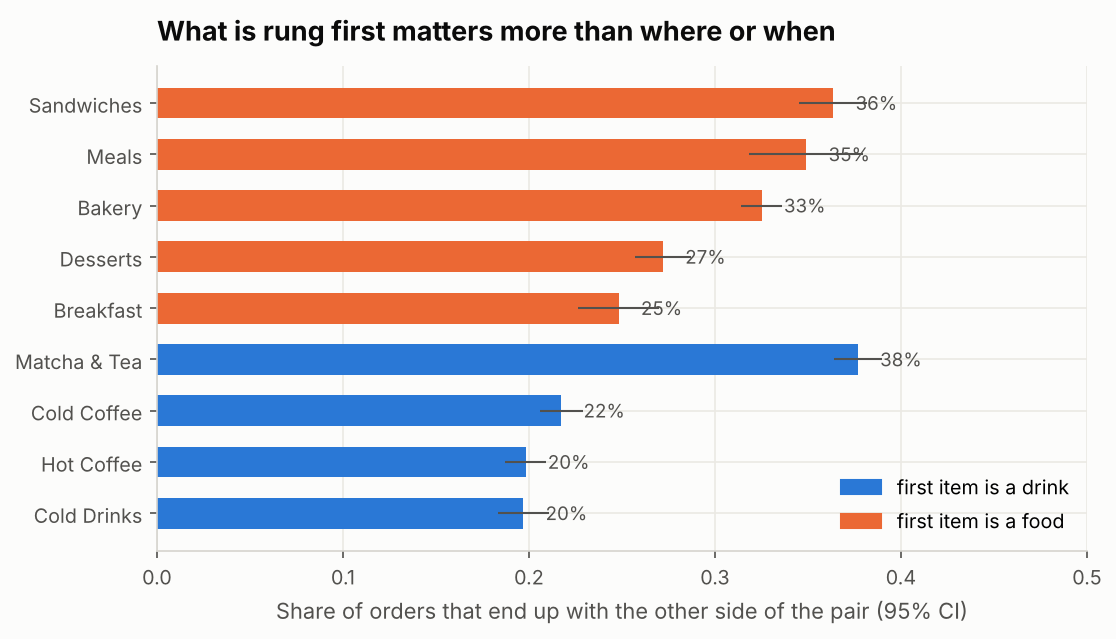

In [3]:
g = orders.groupby(["first_side", "first_category"]).paired.agg(["mean", "size"]).reset_index()
g["se"] = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
g = g.sort_values(["first_side", "mean"])
fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(g))
colors = [viz.BLUE if s == "drink" else viz.ORANGE for s in g.first_side]
ax.barh(ypos, g["mean"], xerr=1.96 * g["se"], color=colors, height=0.6, error_kw={"ecolor": viz.INK_2, "lw": 1})
ax.set_yticks(ypos, g.first_category)
for y, m in zip(ypos, g["mean"]):
    ax.text(m + 0.012, y, f"{m:.0%}", va="center", fontsize=9, color=viz.INK_2)
ax.set_xlabel("Share of orders that end up with the other side of the pair (95% CI)")
ax.set_title("What is rung first matters more than where or when")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=viz.BLUE), plt.Rectangle((0, 0), 1, 1, color=viz.ORANGE)],
          labels=["first item is a drink", "first item is a food"], loc="lower right")
ax.set_xlim(0, 0.5)
viz.savefig(fig, "01_paired_rate_by_first_category")
plt.show()

In [4]:
tests = []
for side in ["drink", "food"]:
    d = orders[orders.first_side == side]
    for by in ["first_category", "first_product", "branch", "daypart", "order_type", "weekend"]:
        r = evidence.chi2_test(d, by, "paired", f"{side}-first: {by} -> paired")
        tests.append(r)
tests = pd.DataFrame(tests)
tests["p_bonferroni"] = np.minimum(tests.p_value * len(tests), 1)
tests[["test", "n", "chi2", "dof", "p_bonferroni", "cramers_v"]].round(4)

,test,n,chi2,dof,p_bonferroni,cramers_v
0,drink-first: first_category -> paired,18644,610.4,3,0.0000,0.181
1,drink-first: first_product -> paired,18644,623.0,22,0.0000,0.183
2,drink-first: branch -> paired,18644,0.2,2,1.0000,0.004
3,drink-first: daypart -> paired,18644,12.6,3,0.0668,0.026
4,drink-first: order_type -> paired,18644,0.1,1,1.0000,0.002
5,drink-first: weekend -> paired,18644,0.2,1,1.0000,0.003
6,food-first: first_category -> paired,15243,97.5,4,0.0000,0.080
7,food-first: first_product -> paired,15243,113.3,21,0.0000,0.086
8,food-first: branch -> paired,15243,0.4,2,1.0000,0.005
9,food-first: daypart -> paired,15243,10.3,3,0.1959,0.026


Category and product of the first item are significant for both directions. Branch, daypart and order type are weak
or absent (tiny Cramér's V). This is why, in notebook 03, a simple "rate by first-item category" baseline matches a
full machine-learning model.

## 2. When an order *does* pair, what gets added?

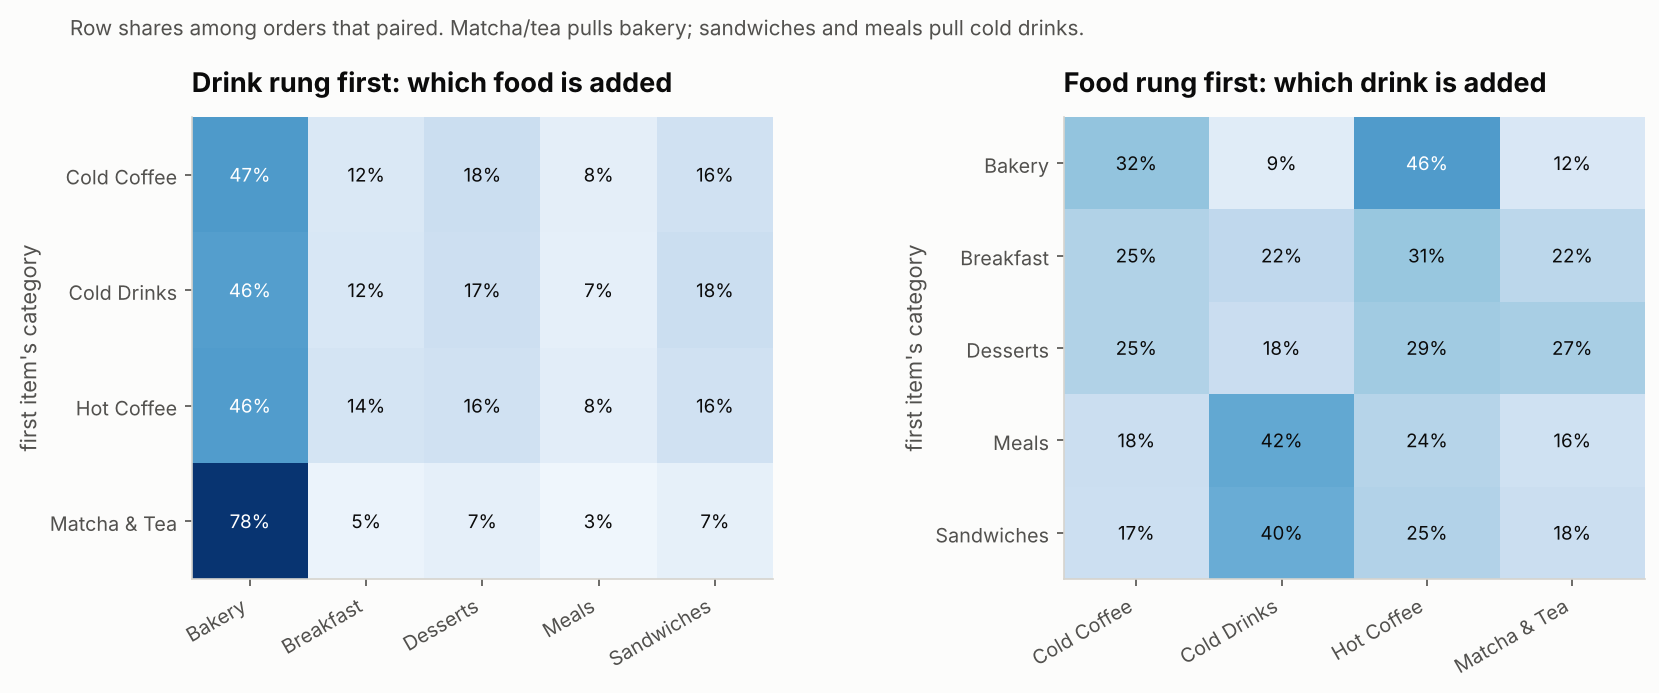

In [5]:
pairs = evidence.paired_orders(lines)
added = data.other_side_first_item(lines, orders)
po = orders[orders.paired].join(added, on="transaction_id")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0), gridspec_kw={"wspace": 0.5})
for ax, side, title in [(axes[0], "drink", "Drink rung first: which food is added"),
                        (axes[1], "food", "Food rung first: which drink is added")]:
    d = po[po.first_side == side]
    tab = pd.crosstab(d.first_category, d.added_category, normalize="index")
    im = ax.imshow(tab.values, cmap=viz.BLUES, vmin=0, vmax=0.8, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), tab.columns, rotation=30, ha="right")
    ax.set_yticks(range(tab.shape[0]), tab.index)
    ax.grid(False)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.45 else viz.INK)
    ax.set_title(title)
    ax.set_ylabel("first item's category")
fig.suptitle("Row shares among orders that paired. Matcha/tea pulls bakery; sandwiches and meals pull cold drinks.",
             x=0.06, ha="left", y=1.05, fontsize=10, color=viz.INK_2)
viz.savefig(fig, "01_what_gets_added")
plt.show()

In [6]:
evidence.conditional_tests(pairs).query("level == 'category / context'")[["test", "n", "chi2", "dof", "p_bonferroni", "cramers_v"]]

,test,n,chi2,dof,p_bonferroni,cramers_v
0,Drink category -> food category,9563,656.4,12,4.617883e-132,0.151
1,Daypart -> food category,9563,202.5,12,5.045007e-36,0.084
2,Branch -> food category,9563,92.1,8,8.805191e-16,0.069
3,Order type -> food category,9563,20.1,4,2.437298e-03,0.046
4,Daypart -> drink category,9563,301.0,9,8.031683e-59,0.102


The tests above pool both directions. Drink category is the strongest driver of the food category added (Cramér's
V 0.15; 0.19-0.22 once split by which side was rung first, see notebook 02). Daypart, branch and order type are
significant but weak. Notebook 02 asks the harder question: is there anything *below* the category level?

## 3. Unit economics: what an add-on is worth at each branch

In [7]:
ue = data.unit_economics(lines)
wide = ue.pivot_table(index=["side", "category", "product"], columns="branch", values=["price", "cost", "unit_gp"])
ratio_cost = (wide["cost"]["Garden"] / wide["cost"]["Harbour"])
ratio_price = (wide["price"]["Garden"] / wide["price"]["Harbour"])
print(f"Garden / Harbour unit cost:  min {ratio_cost.min():.3f}  median {ratio_cost.median():.3f}  max {ratio_cost.max():.3f}  (45 products)")
print(f"Garden / Harbour list price: min {ratio_price.min():.3f}  median {ratio_price.median():.3f}  max {ratio_price.max():.3f}")
print(f"Uptown / Harbour unit cost:  median {(wide['cost']['Uptown'] / wide['cost']['Harbour']).median():.3f}")

Garden / Harbour unit cost:  min 1.426  median 1.430  max 1.439  (45 products)
Garden / Harbour list price: min 0.951  median 0.953  max 0.953
Uptown / Harbour unit cost:  median 0.960


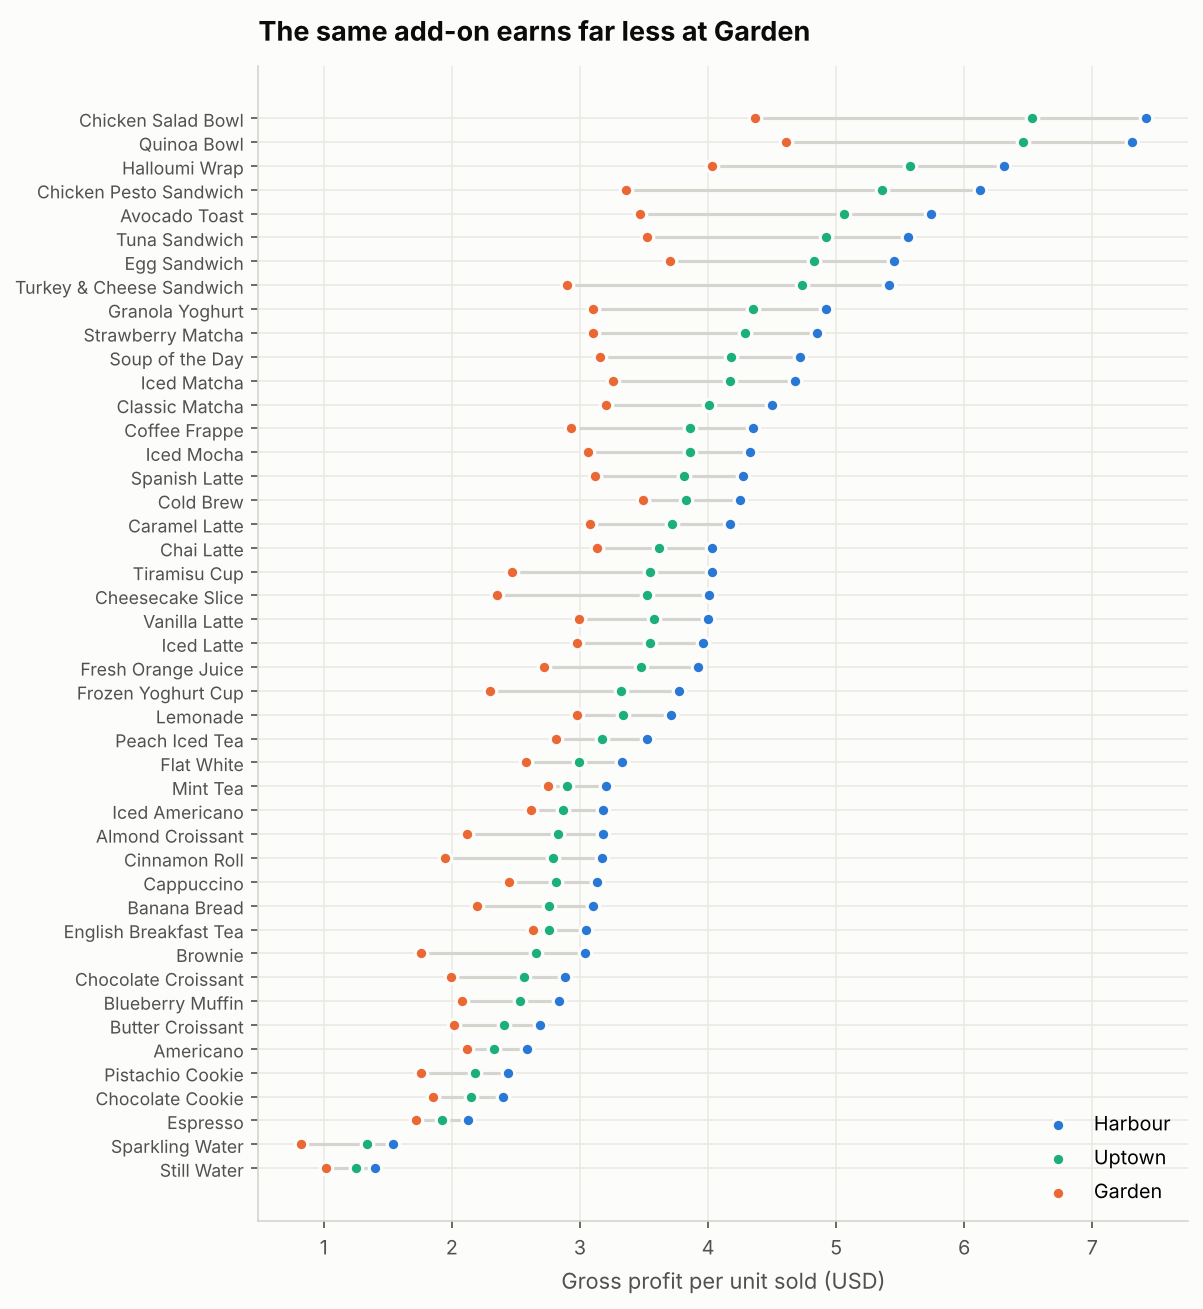

In [8]:
gp = wide["unit_gp"][["Harbour", "Uptown", "Garden"]].reset_index().sort_values("Harbour")
fig, ax = plt.subplots(figsize=(8, 10))
y = np.arange(len(gp))
for b, c in zip(["Harbour", "Uptown", "Garden"], [viz.BLUE, viz.AQUA, viz.ORANGE]):
    ax.scatter(gp[b], y, color=c, s=36, label=b, zorder=3, edgecolor=viz.SURFACE, linewidth=1.5)
ax.hlines(y, gp[["Harbour", "Uptown", "Garden"]].min(axis=1), gp[["Harbour", "Uptown", "Garden"]].max(axis=1), color="#d6d4ce", lw=1.5, zorder=1)
ax.set_yticks(y, gp["product"], fontsize=8.5)
ax.set_xlabel("Gross profit per unit sold (USD)")
ax.set_title("The same add-on earns far less at Garden")
ax.legend(loc="lower right")
viz.savefig(fig, "01_unit_gp_by_branch")
plt.show()

In [9]:
branch_gp = lines.groupby("branch").agg(revenue=("line_revenue", "sum"), gp=("line_gp", "sum"))
branch_gp["gp_margin"] = branch_gp.gp / branch_gp.revenue
# Counterfactual: Garden's units at Garden prices but Harbour-level unit cost
gl = lines[lines.branch == "Garden"].merge(ue[ue.branch == "Harbour"][["product", "cost"]], on="product")
gap_6m = float((gl.quantity * (gl.unit_cost - gl.cost)).sum())
print(branch_gp.round(3).to_string())
print(f"\nGross profit Garden would have kept at Harbour's unit costs: ${gap_6m:,.0f} over 6 months "
      f"(~${gap_6m * 365 / 181:,.0f}/year). This is an upper bound; the cause (supplier terms, recipe, waste, cost "
      f"allocation) is not in the data.")

           revenue        gp  gp_margin
branch                                 
Garden    99748.55  46794.49      0.469
Harbour  150483.58  97753.94      0.650
Uptown    55693.01  34882.06      0.626

Gross profit Garden would have kept at Harbour's unit costs: $15,923 over 6 months (~$32,111/year). This is an upper bound; the cause (supplier terms, recipe, waste, cost allocation) is not in the data.


This is a side finding, not the product, but it matters to the engine: because cost differs per branch while the
pairing behaviour does not, the best add-on to suggest can differ by branch. Notebook 04 shows it does.

## 4. Do discounts create pairs?

In [10]:
d = orders[orders.first_side == "drink"].copy()
any_disc = lines.groupby("transaction_id").discount_rate.max().rename("any_line_discount")
d = d.join(any_disc, on="transaction_id")
naive = d.groupby(d.any_line_discount > 0).paired.agg(["mean", "size"])
naive.index = ["no discounted line", "has a discounted line"]
controlled = d.groupby(d.first_discount > 0).paired.agg(["mean", "size"])
controlled.index = ["first drink at full price", "first drink discounted"]
lines_by_disc = d.groupby(d.any_line_discount > 0).n_lines.mean()
print("NAIVE view (any discounted line in the order):"); print(naive.round(4).to_string())
print(f"\n...but orders with a discounted line have {lines_by_disc[True]:.2f} lines on average vs {lines_by_disc[False]:.2f}:"
      " more lines means more chances to contain a discount AND to contain food.")
print("\nCONTROLLED view (was the first drink itself discounted?):"); print(controlled.round(4).to_string())
ct2 = pd.crosstab(d.first_discount > 0, d.paired)
print(f"\nChi-square test, first-drink discount vs paired: p = {stats.chi2_contingency(ct2)[1]:.3f}")

NAIVE view (any discounted line in the order):
                         mean   size
no discounted line     0.2472  16810
has a discounted line  0.3402   1834

...but orders with a discounted line have 1.70 lines on average vs 1.49: more lines means more chances to contain a discount AND to contain food.

CONTROLLED view (was the first drink itself discounted?):
                             mean   size
first drink at full price  0.2568  17367
first drink discounted     0.2506   1277

Chi-square test, first-drink discount vs paired: p = 0.650


Discounts in this data look like they were applied line by line, at random (about 5-6% of lines get 10% off,
similar across hours and customers). When the first drink was discounted, pairing did not change. We **do not** claim
this proves combo discounts never work (a discount on the add-on, shown upfront, is a different intervention), but
it is the only discount evidence in the file and it gives no reason to lead with discounts. The engine therefore
treats discounts as optional and tests whether they pay.

In [11]:
disc_profile = lines.groupby("category").discount_rate.apply(lambda s: (s > 0).mean()).rename("share_of_lines_discounted")
promo = lines[lines.discount_rate == 0.15].groupby(["branch", "month"]).size().rename("lines_at_15pct")
print(disc_profile.round(3).to_string())
print("\n15% discounts appear only here:"); print(promo.to_string())

category
Bakery          0.054
Breakfast       0.057
Cold Coffee     0.101
Cold Drinks     0.057
Desserts        0.094
Hot Coffee      0.059
Matcha & Tea    0.058
Meals           0.042
Sandwiches      0.055

15% discounts appear only here:
branch   month
Harbour  3        224
         5        280


In [12]:
_ = viz.savetable(ue, "01_unit_economics"), viz.savetable(tests, "01_paired_rate_tests")